In [2]:
%load_ext autoreload
%autoreload 2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.estimators import HillClimbSearch, BIC, BDeu, K2, AIC, BDs, BayesianEstimator, ExpectationMaximization
from pgmpy.estimators.MLE import MaximumLikelihoodEstimator
import networkx as nx
import copy
import logging
import pickle

from utils import get_cpd_complexity, compare_multiple_networks_bootstrap_ll

# Suppress all pgmpy INFO messages
logging.getLogger("pgmpy").setLevel(logging.WARNING)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In this notebook, we proceed with the preprocessed dataset obtained in preprocess.ipynb, where we do exploratory data analysis, drop redundant features and discretize the numerical features for better simplicity in modeling, particularly to ensure sparse conditional probability distributions. After this process, we consider the following features:

- Hours per day (of listening to music) -> discretized into 4 bins
- While working -> binary
- Instrumentalist -> binary
- Composer -> binary
- Fav genre -> categorical
- Exploratory (whether a respondent is frequently switching genres listened to) -> binary
- BPM (of music listened) -> discretized into 4 bins
- Anxiety (self-reported) -> discretized into 4 bins
- Depression (self-reported) -> discretized into 4 bins
- Insomnia (self-reported) -> discretized into 4 bins
- OCD (self-reported) -> discretized into 2 bins
<!-- 
We proceed with using these features to manually build several Bayesian networks, explained in further detail below, as well as infer a network from the data, comparing them through various metrics, interpreting them and drawing conclusions. We then use the optimal network for analyzing its properties and performing inference. -->

In [3]:
df = pd.read_csv('datasets/mxmh_clean.csv')

In [4]:
df.head()

,Hours per day,While working,Instrumentalist,Composer,Fav genre,Exploratory,BPM,Anxiety,Depression,Insomnia,OCD
0,2,Yes,Yes,Yes,Latin,Yes,2,1,0,0,0
1,1,Yes,No,No,Rock,Yes,1,2,1,1,0
2,3,No,No,No,Video game music,No,2,2,2,3,0
3,2,Yes,No,Yes,Jazz,Yes,1,3,2,1,0
4,3,Yes,No,No,R&B,Yes,1,2,1,2,1


In [5]:
df.describe()

,Hours per day,BPM,Anxiety,Depression,Insomnia,OCD
count,609.000000,609.000000,609.000000,609.000000,609.000000,609.000000
mean,1.752053,1.467980,1.927750,1.610837,1.238095,0.315271
std,1.161017,0.561403,0.936136,0.994035,1.053250,0.465006
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000
50%,2.000000,1.000000,2.000000,2.000000,1.000000,0.000000
75%,3.000000,2.000000,3.000000,2.000000,2.000000,1.000000
max,3.000000,3.000000,3.000000,3.000000,3.000000,1.000000


In this work we wish to study the relationship between music taste and forms of internalizing psychopathology (also refered to as "internalization"). As discussed in [1](https://d1wqtxts1xzle7.cloudfront.net/104996401/2012_Miranda_et_al_music-libre.pdf?1692026389=&response-content-disposition=inline%3B+filename%3DMusic_Listening_and_Mental_Health_Variat.pdf&Expires=1763219013&Signature=Xss8qvIdpW6yCI0o141-ej4wbJh~Vs7lVLgAEYGwb6UavPb01bERXl9q-bMl21hhSoFz5HEDjVzZLKQmXomgNu87o1Ky80VqUqciw5e5a~qdRcG8j0WqZvZ8GVN76Z5~OORbcQxRgstbvZ7ih~iGF2vgZ6VO7ycGlZC~GCXx5f0TwmBh5Nd99ayh0PS7~aefTTuSy2mcRcze3UP7jO~9Ked9y~BfVhpjfNP0jQfxkqnGvJIUPYeACYTs1hwc8YNwRmwz7lhfS-r~bMT64GjOuwvdwBNK2Ru7cZO2o8oYbvtm0uwJvKN9LAISjFJwgYaC9u8QKrOaY69N-mgydeyq-w__&Key-Pair-Id=APKAJLOHF5GGSLRBV4ZA) internalizing psychopathology relates several different psychopathologies (including the ones we study but also phobia, suicidal ideation, etc.) and opposes them dimensionally to externalizing psychopathology (e.g. aggression, antisocial behaviour) on the basis of correlations, which themselves indicate underlying biopshychosocial factors.

[1](https://d1wqtxts1xzle7.cloudfront.net/104996401/2012_Miranda_et_al_music-libre.pdf?1692026389=&response-content-disposition=inline%3B+filename%3DMusic_Listening_and_Mental_Health_Variat.pdf&Expires=1763219013&Signature=Xss8qvIdpW6yCI0o141-ej4wbJh~Vs7lVLgAEYGwb6UavPb01bERXl9q-bMl21hhSoFz5HEDjVzZLKQmXomgNu87o1Ky80VqUqciw5e5a~qdRcG8j0WqZvZ8GVN76Z5~OORbcQxRgstbvZ7ih~iGF2vgZ6VO7ycGlZC~GCXx5f0TwmBh5Nd99ayh0PS7~aefTTuSy2mcRcze3UP7jO~9Ked9y~BfVhpjfNP0jQfxkqnGvJIUPYeACYTs1hwc8YNwRmwz7lhfS-r~bMT64GjOuwvdwBNK2Ru7cZO2o8oYbvtm0uwJvKN9LAISjFJwgYaC9u8QKrOaY69N-mgydeyq-w__&Key-Pair-Id=APKAJLOHF5GGSLRBV4ZA) forms a hypothesis based on emotion regulation and gradual development, which implies that music listening might have a small, gradual and cumulative influence on menthal health. The authors of [1](https://d1wqtxts1xzle7.cloudfront.net/104996401/2012_Miranda_et_al_music-libre.pdf?1692026389=&response-content-disposition=inline%3B+filename%3DMusic_Listening_and_Mental_Health_Variat.pdf&Expires=1763219013&Signature=Xss8qvIdpW6yCI0o141-ej4wbJh~Vs7lVLgAEYGwb6UavPb01bERXl9q-bMl21hhSoFz5HEDjVzZLKQmXomgNu87o1Ky80VqUqciw5e5a~qdRcG8j0WqZvZ8GVN76Z5~OORbcQxRgstbvZ7ih~iGF2vgZ6VO7ycGlZC~GCXx5f0TwmBh5Nd99ayh0PS7~aefTTuSy2mcRcze3UP7jO~9Ked9y~BfVhpjfNP0jQfxkqnGvJIUPYeACYTs1hwc8YNwRmwz7lhfS-r~bMT64GjOuwvdwBNK2Ru7cZO2o8oYbvtm0uwJvKN9LAISjFJwgYaC9u8QKrOaY69N-mgydeyq-w__&Key-Pair-Id=APKAJLOHF5GGSLRBV4ZA) also list possible reasons for this influence: "Our conceptual framework argues that everyday music listening may have influences on
internalizing psychopathology because: (a) music can involve emotion regulation and coping; (b)
songs may have social cognitive influences; (c) music can have psychotherapeutic effects. "

[1](https://d1wqtxts1xzle7.cloudfront.net/104996401/2012_Miranda_et_al_music-libre.pdf?1692026389=&response-content-disposition=inline%3B+filename%3DMusic_Listening_and_Mental_Health_Variat.pdf&Expires=1763219013&Signature=Xss8qvIdpW6yCI0o141-ej4wbJh~Vs7lVLgAEYGwb6UavPb01bERXl9q-bMl21hhSoFz5HEDjVzZLKQmXomgNu87o1Ky80VqUqciw5e5a~qdRcG8j0WqZvZ8GVN76Z5~OORbcQxRgstbvZ7ih~iGF2vgZ6VO7ycGlZC~GCXx5f0TwmBh5Nd99ayh0PS7~aefTTuSy2mcRcze3UP7jO~9Ked9y~BfVhpjfNP0jQfxkqnGvJIUPYeACYTs1hwc8YNwRmwz7lhfS-r~bMT64GjOuwvdwBNK2Ru7cZO2o8oYbvtm0uwJvKN9LAISjFJwgYaC9u8QKrOaY69N-mgydeyq-w__&Key-Pair-Id=APKAJLOHF5GGSLRBV4ZA) goes on to conduct a review of the literature and study the possible mechanisms of such an influence, proposing research designs for establishing them. Ultimately, however this work concludes that empirical studies on the subject are few and difficult to draw conclusions from.

A futher analysis of the literature relating to music preference and mental health in adolescents is presented in [2](https://d1wqtxts1xzle7.cloudfront.net/81945163/Can_20Music_20Preference_20Indicate_20Mental_20Health_20Status_20in_20Young_20People-libre.pdf?1646848490=&response-content-disposition=inline%3B+filename%3DCan_Music_Preference_Indicate_Mental_Hea.pdf&Expires=1763215966&Signature=ZrBga8iQWJxGBwzJgYMjQ62-LPrehdl4GLD3l14JQQP7koZy6H09Cjr3Z~QRe3H4H-iqn07qBHrn60lE5aO369TfSPgVo~OsUZbP-vhO7NjbPAhWchz5BqWsoWHYObbPOqiddqVGyGUjmPrf03yUwPYrG5UbOXOfKRFC7JDFhL~UM584QLnoKAUxSDJFl~ZXFGlwW50zachruFEp39zme45Laa-a4vvWSWMAPE8x8fI2dE~zL5yJswC8M~KJK6rEaTdiFUELvi24lkIdyXJSEXyZUBCVDH8lbee4lFOydOM6vDwEIXJBJOI2olE25uLR3u25WFq7VLe5KJntrQS20A__&Key-Pair-Id=APKAJLOHF5GGSLRBV4ZA). Interestingly, here the authors conclude from their review that a more likely connection between the two phenomena is that music taste might influenced by emotional factors. 

Inspired by [1](https://d1wqtxts1xzle7.cloudfront.net/104996401/2012_Miranda_et_al_music-libre.pdf?1692026389=&response-content-disposition=inline%3B+filename%3DMusic_Listening_and_Mental_Health_Variat.pdf&Expires=1763219013&Signature=Xss8qvIdpW6yCI0o141-ej4wbJh~Vs7lVLgAEYGwb6UavPb01bERXl9q-bMl21hhSoFz5HEDjVzZLKQmXomgNu87o1Ky80VqUqciw5e5a~qdRcG8j0WqZvZ8GVN76Z5~OORbcQxRgstbvZ7ih~iGF2vgZ6VO7ycGlZC~GCXx5f0TwmBh5Nd99ayh0PS7~aefTTuSy2mcRcze3UP7jO~9Ked9y~BfVhpjfNP0jQfxkqnGvJIUPYeACYTs1hwc8YNwRmwz7lhfS-r~bMT64GjOuwvdwBNK2Ru7cZO2o8oYbvtm0uwJvKN9LAISjFJwgYaC9u8QKrOaY69N-mgydeyq-w__&Key-Pair-Id=APKAJLOHF5GGSLRBV4ZA)  and [2](https://d1wqtxts1xzle7.cloudfront.net/81945163/Can_20Music_20Preference_20Indicate_20Mental_20Health_20Status_20in_20Young_20People-libre.pdf?1646848490=&response-content-disposition=inline%3B+filename%3DCan_Music_Preference_Indicate_Mental_Hea.pdf&Expires=1763215966&Signature=ZrBga8iQWJxGBwzJgYMjQ62-LPrehdl4GLD3l14JQQP7koZy6H09Cjr3Z~QRe3H4H-iqn07qBHrn60lE5aO369TfSPgVo~OsUZbP-vhO7NjbPAhWchz5BqWsoWHYObbPOqiddqVGyGUjmPrf03yUwPYrG5UbOXOfKRFC7JDFhL~UM584QLnoKAUxSDJFl~ZXFGlwW50zachruFEp39zme45Laa-a4vvWSWMAPE8x8fI2dE~zL5yJswC8M~KJK6rEaTdiFUELvi24lkIdyXJSEXyZUBCVDH8lbee4lFOydOM6vDwEIXJBJOI2olE25uLR3u25WFq7VLe5KJntrQS20A__&Key-Pair-Id=APKAJLOHF5GGSLRBV4ZA) we aim to use the Bayesian networks to study the two hypotheses "Music taste influences internalization" and "Internalization influences music taste". For this puspose we follow the principal of causal discovery using score funcions and use the dataset ["Music & Mental Health Survey"](https://www.kaggle.com/datasets/catherinerasgaitis/mxmh-survey-results), uploaded to Kaggel by Catherine Rasgaitis 

Our use of variables such as "Composer", "Exploratory", "Hours per day", "While working" gives further context to the behaviours of music listening besides the subjects' preference, which [1](https://d1wqtxts1xzle7.cloudfront.net/104996401/2012_Miranda_et_al_music-libre.pdf?1692026389=&response-content-disposition=inline%3B+filename%3DMusic_Listening_and_Mental_Health_Variat.pdf&Expires=1763219013&Signature=Xss8qvIdpW6yCI0o141-ej4wbJh~Vs7lVLgAEYGwb6UavPb01bERXl9q-bMl21hhSoFz5HEDjVzZLKQmXomgNu87o1Ky80VqUqciw5e5a~qdRcG8j0WqZvZ8GVN76Z5~OORbcQxRgstbvZ7ih~iGF2vgZ6VO7ycGlZC~GCXx5f0TwmBh5Nd99ayh0PS7~aefTTuSy2mcRcze3UP7jO~9Ked9y~BfVhpjfNP0jQfxkqnGvJIUPYeACYTs1hwc8YNwRmwz7lhfS-r~bMT64GjOuwvdwBNK2Ru7cZO2o8oYbvtm0uwJvKN9LAISjFJwgYaC9u8QKrOaY69N-mgydeyq-w__&Key-Pair-Id=APKAJLOHF5GGSLRBV4ZA) expresses as important and sometimes lacking in existing research.

We model different Bayesian networks manually (Mental health influences taste vs. taste influences influences health) for each assumption. Both networks share a set of edges that are unrelated to the causal direction dilemma, represented in personal_causes and genre_causes. Otherwise, the relations between genres (and features related to genres, such as BPM) and the conditions (Anxiety, Depression, Insomnia, OCD) are mirrored.

Inspired by 1 and 2 we aim to use the Bayesian networks to study the two hypotheses "Music taste influences internalization" and "Internalization influences music taste". For this puspose we use the dataset "Music \& Mental Health Survey", uploaded to Kaggel by Catherine Rasgaitis. Our goal is to evaluate different ways of modeling the domain and preform inference.
<!-- TODO say what our aim is also with the queries -->


<!--  -->

<!-- Our interest is to use causal discovery with score functions in order to see what the data from the above mentioned database says about these hypotheses by comparing said Bayesian networks. We expand our reasoning beyond the simple use of the dataset by also considering priors on the distributions of the mental illnesses present in our data. Finally, we use a Hill-Climbing approach to obtain a structure of a Bayesian network obtained from the data and compare it the those manually defined by us. -->

<!-- Finally, after we build all three networks as discrete Bayesian networks, we also visualize them with NetworkX. -->

# Definition and Evaluation of Manually Defined Networks

In [6]:
personal_causes = [
    ('Instrumentalist', 'Composer'),
    ('Instrumentalist', 'Hours per day'),
    ('Instrumentalist', 'Fav genre'),
    ('Composer', 'Hours per day'),
    ('Composer', 'Fav genre'),
    ('While working', 'Hours per day'),
]

genre_causes = [
    ('Fav genre', 'BPM')
]

mental_health_influences_taste = [
    ('Anxiety', 'Fav genre'),
    ('Anxiety', 'BPM'),
    ('Anxiety', 'Hours per day'),
    ('Anxiety', 'Exploratory'),
    ('Depression', 'Fav genre'),
    ('Depression', 'BPM'),
    ('Depression', 'Hours per day'),
    ('Depression', 'Exploratory'),
    ('Insomnia', 'Fav genre'),
    ('Insomnia', 'BPM'),
    ('Insomnia', 'Hours per day'),
    ('Insomnia', 'Exploratory'),
    ('OCD', 'Fav genre'),
    ('OCD', 'BPM'),
    ('OCD', 'Hours per day'),
    ('OCD', 'Exploratory')
] + personal_causes + genre_causes


taste_influences_mental_health = [
    ('Fav genre', 'Anxiety'),
    ('BPM', 'Anxiety'),
    ('Hours per day', 'Anxiety'),
    ('Exploratory', 'Anxiety'),
    ('Fav genre', 'Depression'),
    ('BPM', 'Depression'),
    ('Hours per day', 'Depression'),
    ('Exploratory', 'Depression'),
    ('Fav genre', 'Insomnia'),
    ('BPM', 'Insomnia'),
    ('Hours per day', 'Insomnia'),
    ('Exploratory', 'Insomnia'),
    ('Fav genre', 'OCD'),
    ('BPM', 'OCD'),
    ('Hours per day', 'OCD'),
    ('Exploratory', 'OCD')
] + personal_causes + genre_causes

In [7]:
BN_MHIT = DiscreteBayesianNetwork(mental_health_influences_taste)
BN_TIMH = DiscreteBayesianNetwork(taste_influences_mental_health)

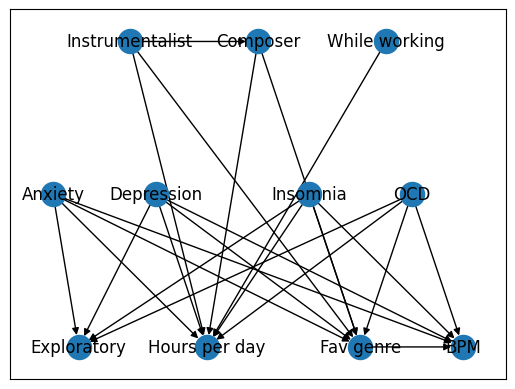

In [34]:
G = nx.DiGraph()
G.add_edges_from(BN_MHIT.edges())
pos = {
        'Instrumentalist': [0.25, 0],
        'Composer': [0.5, 0],
        'While working': [0.75, 0],
        'Anxiety': [0.1, -0.5],
        'Depression': [0.3, -0.5],
        'Insomnia': [0.6, -0.5],
        'OCD': [0.8, -0.5],
        'Exploratory': [0.15, -1],
        'Hours per day': [0.4, -1],
        'Fav genre': [0.7, -1],
        'BPM': [0.9, -1]
}
# plt.subplots(1, 1, figsize=(12, 12))
nx.draw_networkx(G, pos=pos)


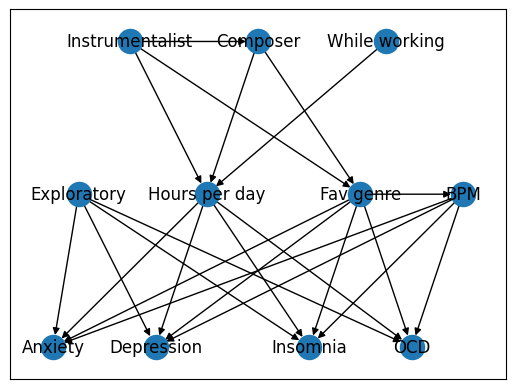

In [36]:
G = nx.DiGraph()
G.add_edges_from(BN_TIMH.edges())
pos = {
        'Instrumentalist': [0.25, 0],
        'Composer': [0.5, 0],
        'While working': [0.75, 0],
        'Anxiety': [0.1, -1],
        'Depression': [0.3, -1],
        'Insomnia': [0.6, -1],
        'OCD': [0.8, -1],
        'Exploratory': [0.15, -0.5],
        'Hours per day': [0.4, -0.5],
        'Fav genre': [0.7, -0.5],
        'BPM': [0.9, -0.5]
}
# plt.subplots(1, 1, figsize=(12, 12))
nx.draw_networkx(G, pos = pos)

We then fit estimator functions to each network in order to obtain the conditional probability distributions learned from the data. For the manually constructed networks we use a simple Maximum Likelihood Estimeation. Since the MLE works only for fully known variables, we use Expectation-Maximization with our latent network, which includes the latent variable "Internalization".

In [10]:
MHIT_copy = copy.deepcopy(BN_MHIT)
TIMH_copy = copy.deepcopy(BN_TIMH)

MHIT_estimator = MaximumLikelihoodEstimator(MHIT_copy, df)
TIMH_estimator = MaximumLikelihoodEstimator(TIMH_copy, df)

with open('pickles/MHIT_estimator.pkl', 'wb') as file:
    pickle.dump(MHIT_estimator, file)
with open('pickles/TIMH_estimator.pkl', 'wb') as file:
    pickle.dump(TIMH_estimator, file)

MHIT_estimation = MHIT_estimator.get_parameters()
TIMH_estimation = TIMH_estimator.get_parameters()


In [11]:
for cpd in MHIT_estimation:
    MHIT_copy.add_cpds(cpd)

for cpd in TIMH_estimation:
    TIMH_copy.add_cpds(cpd)

As mentioned before, we are interested in judging the fitness of the Mental Health Causes Taste assumption vs. the inverse. For this, we used two different scoring functions (BIC, BDeu), with each scoring function working according to different criteria, and the data was sampled using bootstrapping. A summary of each scoring method is given below.

## BIC (Bayesian Information Criterion)

**BIC** is a penalized log-likelihood score of the form:

$$
\phi(B \mid T) = \mathrm{LL}(B \mid T) - f(N) \cdot |B|
$$

where |B| is the number of parameters in the network and f(N) is the penalty function.

The penalty function is defined as:

$$
f(N) = \tfrac{1}{2}\log N \quad
$$

The log-likelihood of the data T given the network B is:

$$
\mathrm{LL}(B \mid T) = \sum_{i=1}^{n} \sum_{j=1}^{q_i} \sum_{k=1}^{r_i} N_{ijk} \log \frac{N_{ijk}}{N_{ij}}
$$


where:

$$
n \text{ : number of nodes in the network}
$$

$$
r_i \text{ : number of states of node } i
$$

$$
q_i \text{ : number of parent configurations of node } i
$$

$$
N_{ijk} \text{ : number of instances where node } i \text{ is in state } k \text{ and its parents are in configuration } j
$$

$$
N_{ij} = \sum_{k=1}^{r_i} N_{ijk}
$$

$$
N \text{ : sample size}
$$


---

## BDeu (Bayesian Dirichlet equivalent uniform)

BDeu is a **Bayesian score** with a uniform Dirichlet prior:

$$
\mathrm{BDeu}(B, T) = \log P(B) 
+ \sum_{i=1}^{n} \sum_{j=1}^{q_i} \Bigg[
\log \frac{\Gamma\left(\frac{\alpha}{q_i}\right)}{\Gamma\left(N_{ij} + \frac{\alpha}{q_i}\right)}
+ \sum_{k=1}^{r_i} \log \frac{\Gamma\left(N_{ijk} + \frac{\alpha}{r_i q_i}\right)}{\Gamma\left(\frac{\alpha}{r_i q_i}\right)}
\Bigg]
$$

---

## Variable Definitions

$$
n \text{ : number of nodes in the network}
$$

$$
r_i \text{ : number of states of node } i
$$

$$
q_i \text{ : number of parent configurations of node } i
$$

$$
N_{ijk} \text{ : number of instances where node } i \text{ is in state } k \text{ and its parents are in configuration } j
$$

$$
N_{ij} = \sum_{k=1}^{r_i} N_{ijk}
$$

$$
\alpha \text{ : equivalent sample size}
$$

$$
\Gamma \text{ : Gamma function}
$$

$$
P(B) \text{ : prior probability of the network structure}
$$

---

These scoring functions balance **goodness-of-fit** and **model complexity**, with BIC using penalized likelihood and BDeu incorporating Bayesian priors.


Both causal directions won one scoring test each. This can be explained through the nature of the scoring functions. Namely, the score that prefers TIMH (BIC) penalizes model complexity, and TIMH has much simpler CPDs with less parameters than MHIT, as can be seen below. Meanwhile, BDeu has no penalizing terms and focuses purely on the fit to the data. Thus, which network is better depends on the importance given to model complexity as a factor. Since we are mainly concerned with quality of fit, and can tolerate a more parameter-heavy model, we consider Mental-Health-Implies-Taste as the more likely causal direction. Still, this is a complex problem for which consensus has still not been reached, and our results may be influenced by the same risk of biased self-reporting mentioned above.

In [12]:
# Number of bootstrap resamples
n_bootstrap = 50
random_state = 42
rng = np.random.default_rng(random_state)

# Containers for bootstrap scores
bootstrap_scores = {
    'BIC':      {'MHIT': [], 'TIMH': []},
    'BDeu':     {'MHIT': [], 'TIMH': []}
}

# Perform bootstrapping
for i in range(n_bootstrap):
    sample_idx = rng.choice(df.index, size=len(df), replace=True)
    df_sample = df.iloc[sample_idx].reset_index(drop=True)

    # Compute scores for BIC
    bic = BIC(df_sample)
    bic_MHIT       = bic.score(MHIT_copy)
    bic_TIMH       = bic.score(TIMH_copy)

    # Compute scores for BDeu
    bdeu = BDeu(df_sample)
    bdeu_MHIT       = bdeu.score(MHIT_copy)
    bdeu_TIMH       = bdeu.score(TIMH_copy)

    # Store results
    bootstrap_scores['BIC']['MHIT'].append(bic_MHIT)
    bootstrap_scores['BIC']['TIMH'].append(bic_TIMH)

    bootstrap_scores['BDeu']['MHIT'].append(bdeu_MHIT)
    bootstrap_scores['BDeu']['TIMH'].append(bdeu_TIMH)

# Compute means and standard deviations
rows = []
for score_type, values in bootstrap_scores.items():
    MHIT_mean       = np.mean(values['MHIT'])
    TIMH_mean       = np.mean(values['TIMH'])

    MHIT_std        = np.std(values['MHIT'])
    TIMH_std        = np.std(values['TIMH'])

    # Decide best model by highest mean score
    means = {
        'MHIT': MHIT_mean,
        'TIMH': TIMH_mean,
    }
    better = max(means, key=means.get)

    rows.append({
        'Score Type': score_type,
        'MHIT (mean)': MHIT_mean,
        'MHIT (std)': MHIT_std,
        'TIMH (mean)': TIMH_mean,
        'TIMH (std)': TIMH_std,
        'Better Model': better
    })

# Create summary DataFrame
score_comparison = pd.DataFrame(rows)

score_comparison


,Score Type,MHIT (mean),MHIT (std),TIMH (mean),TIMH (std),Better Model
0,BIC,-59170.344018,1123.151179,-22026.337870,627.159050,TIMH
1,BDeu,-7781.849533,78.349633,-7976.568509,89.541185,MHIT


In [13]:
MHIT_total, MHIT_detail = get_cpd_complexity(MHIT_copy)
TIMH_total, TIMH_detail = get_cpd_complexity(TIMH_copy)

print("===== TOTAL MODEL DIMENSIONS =====")
print(f"MHIT total parameters : {MHIT_total}")
print(f"TIMH total parameters : {TIMH_total}")

print("\n===== PER-NODE PARAMETER COUNTS =====")
print("\n--- MHIT ---")
for node, params in MHIT_detail.items():
    print(f"{node}: {params}")

print("\n--- TIMH ---")
for node, params in TIMH_detail.items():
    print(f"{node}: {params}")

===== TOTAL MODEL DIMENSIONS =====
MHIT total parameters : 17038
TIMH total parameters : 5257

===== PER-NODE PARAMETER COUNTS =====

--- MHIT ---
Anxiety: 3
Fav genre: 7680
BPM: 6144
Hours per day: 3072
Exploratory: 128
Depression: 3
Insomnia: 3
OCD: 1
Instrumentalist: 1
Composer: 2
While working: 1

--- TIMH ---
Fav genre: 60
Anxiety: 1536
BPM: 48
Hours per day: 24
Exploratory: 1
Depression: 1536
Insomnia: 1536
OCD: 512
Instrumentalist: 1
Composer: 2
While working: 1


Upon first consideration the results of this comparison seem mixed and given the unreliability of our data we are in no way capable of making conclusions on any of the hypotheses. That being said, two considerations lead us to reguard "mental health influences music taste" as the better hypothesis at least in some sense:
1. [2](https://d1wqtxts1xzle7.cloudfront.net/81945163/Can_20Music_20Preference_20Indicate_20Mental_20Health_20Status_20in_20Young_20People-libre.pdf?1646848490=&response-content-disposition=inline%3B+filename%3DCan_Music_Preference_Indicate_Mental_Hea.pdf&Expires=1763215966&Signature=ZrBga8iQWJxGBwzJgYMjQ62-LPrehdl4GLD3l14JQQP7koZy6H09Cjr3Z~QRe3H4H-iqn07qBHrn60lE5aO369TfSPgVo~OsUZbP-vhO7NjbPAhWchz5BqWsoWHYObbPOqiddqVGyGUjmPrf03yUwPYrG5UbOXOfKRFC7JDFhL~UM584QLnoKAUxSDJFl~ZXFGlwW50zachruFEp39zme45Laa-a4vvWSWMAPE8x8fI2dE~zL5yJswC8M~KJK6rEaTdiFUELvi24lkIdyXJSEXyZUBCVDH8lbee4lFOydOM6vDwEIXJBJOI2olE25uLR3u25WFq7VLe5KJntrQS20A__&Key-Pair-Id=APKAJLOHF5GGSLRBV4ZA) draws on conclusions from the existing literature on suicidal ideation to, in order to state that music listening habits are likely indicative of existing vulnerabilities, rather than influencial. Since suicidal ideation is a form of internalizaed psychopathology, we suppose that the same might also be true for the mental illnesses we consider.
2. The BIC score used in the comparison above is heavily influenced by the number of parameters in the network, which in the case of TIMH is smaller. This leads us to consider the BDeu score as more meaningful in comparing the two networks.

Following these considerations we go on to run interesting queries on the MHIT network in inference_and_properties.ipynb. In this notebook we explore some more ways of modeling the domain by:

1. introducing prior knowledge to account for biases in the dataset
2. adding a latent variable for internalization
3. applying a score based learning approach to obtain a further network structure

# Introducing Prior Knowledge with Bayesian Estimation

Having estimated the CPDs for the above networks from our dataset, we also consider that the way in which the [dataset](https://www.kaggle.com/datasets/catherinerasgaitis/mxmh-survey-results) was collected (by an online survey) might introduce bias to the prior distributions of the variables. Indeed, this is particularly obvious with the entries for mental illnesses as seen below. A further culplrit of the difference between the real distributions found by the studies we use as reference (
[3](https://www.cdc.gov/nchs/products/databriefs/db378.htm), [4](https://www.cdc.gov/nchs/products/databriefs/db379.htm#:~:text=The%20total%20percentage%20of%20adults,those%20aged%2065%20and%20over.), [5](https://www.cdc.gov/nchs/products/databriefs/db462.htm), [6](https://www.sciencedirect.com/science/article/pii/S0278584605003465)) and the data we use is the ambiguity of the 0 to 10 ranking scale and our use of bins in the preprocessing stage.


<!-- Our next interest is to consider a network where prior knowledge has been injected in order to influence the probability distributions. We consider the general prevalence rates of Anxiety, Depression, Insomnia and OCD found in the literature, and add pseudo-counts corresponding to their distributions. For simplicity, we choose the Mental Health Causes Taste network, where the four conditions have no parent nodes and thus we can introduce the priors in a simple way, making minimal assumptions about the CPDs of these conditions given other variables.

Our prior is quite strong, significantly altering the raw distributions. The scaling factor of 5 was chosen in order to balance out a weak prior vs. a prior that completely overwhelms the data, so the resulting CPDs are a middle ground. -->

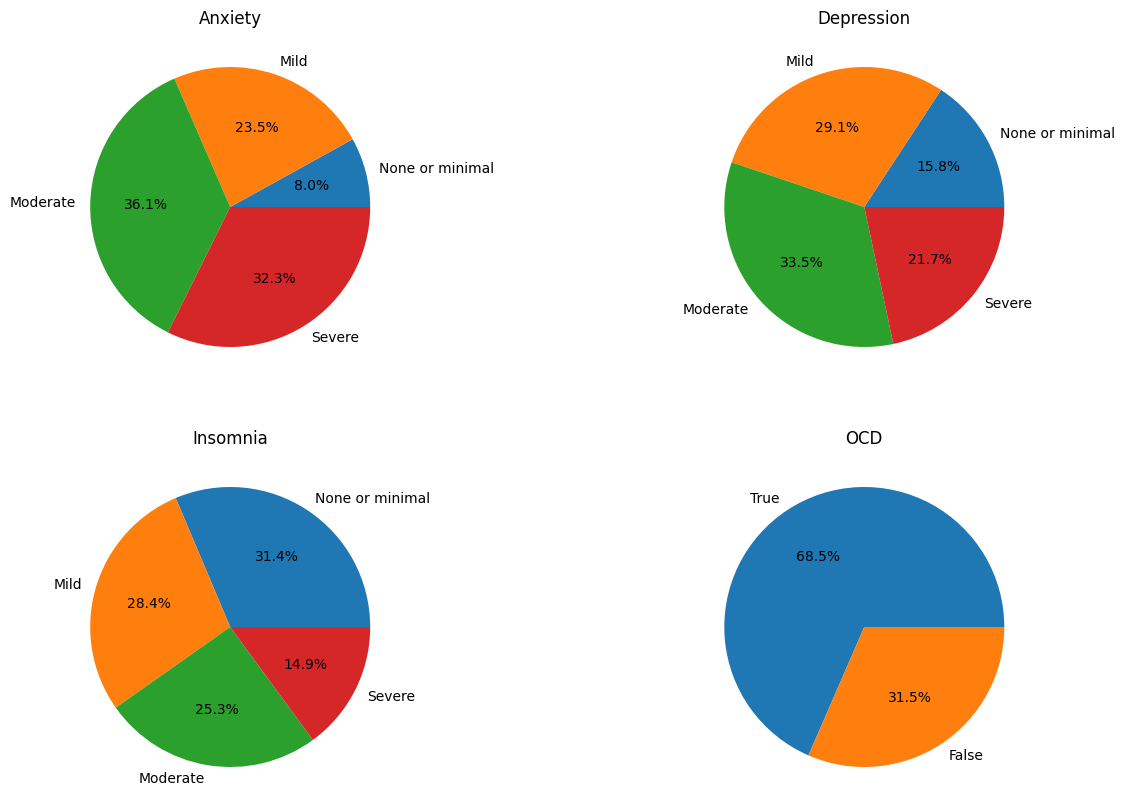

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
axes = axes.flatten()
illnesses_labels = {
    "Anxiety" : ["None or minimal", "Mild", "Moderate", "Severe"],
    "Depression" : ["None or minimal", "Mild", "Moderate", "Severe"],
    "Insomnia": ["None or minimal", "Mild", "Moderate", "Severe"],
    "OCD": ["True", "False"]
}

for i, column in enumerate(illnesses_labels.keys()):
    values = df[column].value_counts().sort_index()
    
    axes[i].pie(values, labels=illnesses_labels[column], autopct='%1.1f%%')
    axes[i].title.set_text(column)

Compare the above figures with the following results of the aforementioned studies. For
1. Anxiety [(3)](https://www.cdc.gov/nchs/products/databriefs/db378.htm)


![image](figures/anxiety_dist.png)


3. Depression [(4)](https://www.cdc.gov/nchs/products/databriefs/db379.htm#:~:text=The%20total%20percentage%20of%20adults,those%20aged%2065%20and%20over.)


![image](figures/depression_dist.png)

3. Insomnia (participants reported how often they take sleeping medication) [(5)](https://www.cdc.gov/nchs/products/databriefs/db462.htm)

![image](figures/use_of_sleep_medication.png)

4. OCD: according to [6](https://www.sciencedirect.com/science/article/pii/S0278584605003465) the prevelance of OCD ranges between 1 and 2.3%

This motivates us the estimate the CPTs for another network levaraging pgmpy's Bayesian Estimator and it's ability to introduce prior knowledge. Here, we itroduce a prior as a pseudo count which helps us get closer to the distributions of the mental illnesses indicated in the aforementioned studies. Since pgmpy(TODO add source) expects prior knowledge to be defined in the form of pseudo counts, we asume for the sake of the example that we've observed 10000 individuals and found a distribution of mental illneses similar to the one reported in the above studies.

In [15]:
custom_priors = {
    "Anxiety": 10000 * np.array([[0.84, 0.10, 0.3, 0.03]]).T,
    "Depression": 10000 *np.array([[0.81, 0.12, 0.4, 0.3]]).T,
    "Insomnia": 10000 *np.array([[0.82, 0.10, 0.2, 0.6]]).T,
    "OCD": 10000 * np.array([[0.98, 0.2]]).T
}

# Create the estimator
MHIT_prior_copy = copy.deepcopy(MHIT_copy)
MHIT_prior_estimator = BayesianEstimator(MHIT_copy, df)

# Fit with custom priors (applied only to the specified variables)
for node in MHIT_prior_copy.nodes():
    if node in custom_priors:
      cpd = MHIT_prior_estimator.estimate_cpd(
          node,
          prior_type="dirichlet",
          pseudo_counts=custom_priors[node]  # only for selected variables
      )
    else:
        # Default prior for other nodes
        cpd = MHIT_prior_estimator.estimate_cpd(node, prior_type="BDeu", equivalent_sample_size=10)
    MHIT_prior_copy.add_cpds(cpd)

As seen in the below coparision the resulting CPDs more closely resemble the likelihood of occurence of the mental illneses that we would expect, having observed the studies.
<!-- The main advantage of this approach lies in its ability to capture prior knowledge, which in our case means that we obtain CPTs that more closely resemble the distributions of mental illnesses stated in the above mentioned studies.  -->

In [16]:
print("\n==================== COMPARING CPDs ====================\n")

for node in custom_priors.keys():
    print(f"===== {node} =====")
    
    # Original CPD
    orig_cpd = MHIT_copy.get_cpds(node)
    print("\n--- Original CPD ---")
    print(orig_cpd)
    
    # CPD with custom prior
    new_cpd = MHIT_prior_copy.get_cpds(node)
    print("\n--- CPD with Custom Prior ---")
    print(new_cpd)
    
    print("\n--------------------------------------------------------\n")


==================== COMPARING CPDs ====================

===== Anxiety =====

--- Original CPD ---
+------------+-----------+
| Anxiety(0) | 0.0804598 |
+------------+-----------+
| Anxiety(1) | 0.234811  |
+------------+-----------+
| Anxiety(2) | 0.361248  |
+------------+-----------+
| Anxiety(3) | 0.323481  |
+------------+-----------+

--- CPD with Custom Prior ---
+------------+-----------+
| Anxiety(0) | 0.634834  |
+------------+-----------+
| Anxiety(1) | 0.0858817 |
+------------+-----------+
| Anxiety(2) | 0.241942  |
+------------+-----------+
| Anxiety(3) | 0.0373432 |
+------------+-----------+

--------------------------------------------------------

===== Depression =====

--- Original CPD ---
+---------------+----------+
| Depression(0) | 0.157635 |
+---------------+----------+
| Depression(1) | 0.29064  |
+---------------+----------+
| Depression(2) | 0.334975 |
+---------------+----------+
| Depression(3) | 0.216749 |
+---------------+----------+

--- CPD with Cus

# Manual Network Definition with Latent Variable

In addition, in the TIMH case, we consider the possibility of a latent variable: namely, the above mentioned internalization dimention used in psychology. Thus, a case where taste influences internalization, which in turn influences specific conditions, was also built. The causal chain of internalization -> specific conditions -> genre preferences is not considered, because it does not simplify the graph and does not have an effect of the CPDs.

The main advantage in this case is that we obtain smaller CPTs for the leaves of the network, which might make querying more efficient.
<!-- Explain wether information is lost using results from queries -->

In [17]:
taste_influences_mental_health_latent = [
    ('Internalization', 'Anxiety'),
    ('Internalization', 'Depression'),
    ('Internalization', 'Insomnia'),
    ('Internalization', 'OCD'),
    ('Fav genre', 'Internalization'),
    ('BPM', 'Internalization'),
    ('Hours per day', 'Internalization'),
    ('Exploratory', 'Internalization')
] + personal_causes + genre_causes

BN_TIMH_latent = DiscreteBayesianNetwork(taste_influences_mental_health_latent, latents= {"Internalization"})

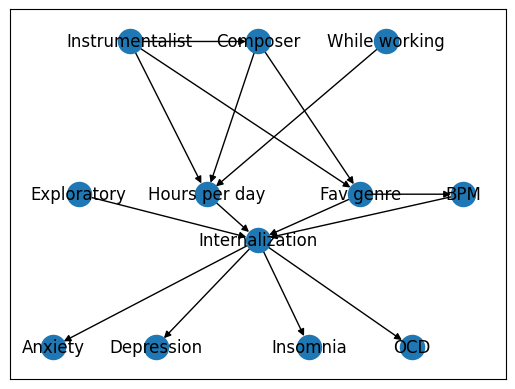

In [40]:
G = nx.DiGraph()
G.add_edges_from(BN_TIMH_latent.edges())
pos = {'Instrumentalist': [0.25, 0],
        'Composer': [0.5, 0],
        'While working': [0.75, 0],
        'Anxiety': [0.1, -1],
        'Depression': [0.3, -1],
        'Insomnia': [0.6, -1],
        'OCD': [0.8, -1],
        'Exploratory': [0.15, -0.5],
        'Hours per day': [0.4, -0.5],
        'Fav genre': [0.7, -0.5],
        'BPM': [0.9, -0.5],
        'Internalization': [0.5, -0.65],
}
# plt.subplots(1, 1, figsize=(12, 12))
nx.draw_networkx(G, pos = pos)

In [19]:
TIMH_latent_copy = copy.deepcopy(BN_TIMH_latent)
TIMH_latent_estimator = ExpectationMaximization(TIMH_latent_copy, df)

with open('pickles/TIMH_latent_estimator.pkl', 'wb') as file:
    pickle.dump(TIMH_latent_estimator, file)
TIMH_latent_estimation = TIMH_latent_estimator.get_parameters(latent_card={"Internalization": 2})

for cpd in TIMH_latent_estimation:
    TIMH_latent_copy.add_cpds(cpd)


  0%|          | 0/100 [00:00<?, ?it/s]

# Score Based Structure Learning
In order to analyze the topology of the networks manually defined by us with respect to the dataset (TODO add source), we propose comparing it to a further network, derived by means of structure learning using one of the score functions we introduced above.

In the following cell we use a simple Hill Climbing search which attempts to optimize the BIC score of the network. 


In [20]:
# use hill climb search to orient the edges:
hc = HillClimbSearch(df)
learned_network = hc.estimate(tabu_length=10, scoring_method=BIC(df))

with open('pickles/learned_model.pkl', 'wb') as file:
    pickle.dump(learned_network, file)
print("Part 2) Model:    ", learned_network.edges())

# Convert DAG to BayesianNetwork
learned_bn = DiscreteBayesianNetwork(learned_network.edges())

# Fit CPDs using data
learned_estimator = MaximumLikelihoodEstimator(learned_bn, df)

with open('pickles/learned_estimator.pkl', 'wb') as file:
    pickle.dump(learned_estimator, file)

cpds = learned_estimator.get_parameters()

for cpd in cpds:
    learned_bn.add_cpds(cpd)
learned_bn_copy = copy.deepcopy(learned_bn)

  0%|          | 0/1000000 [00:00<?, ?it/s]

Part 2) Model:     [('While working', 'Hours per day'), ('While working', 'Exploratory'), ('Instrumentalist', 'Composer'), ('Anxiety', 'Depression'), ('Anxiety', 'OCD'), ('Depression', 'Insomnia')]


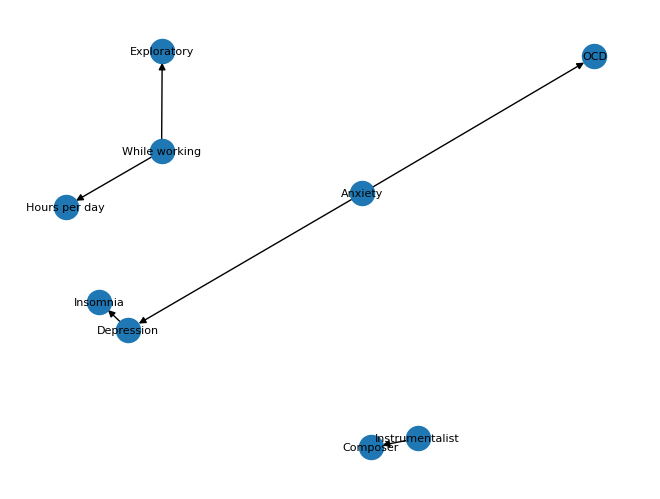

In [21]:
G = nx.DiGraph()
G.add_edges_from(learned_network.edges())
pos = nx.spring_layout(G)  
nx.draw(
    G, 
    pos,
    with_labels=True,
    font_size  = 8
)

As we can see, this approach splits the graph in 3 completely independent subgraphs. A possible reason for this might be that the dataset actually implies a very weak or no dependence between the features we consider as part of the hypothesis dilemma, as the subgraphs here show dependencies between variables that are more self-explanatory (for example it is intuitivlely obvious that wether someone plays an instrument influences wether they are also a composer).

# Final Comparison with bootstrapped Log-Likelihood

As a final consideration, we take the comparison of bootstrapped Log-Likelihood between some of the networks that were constructed. There is an important limitation to this approach, which is that it cannot take into account features unseen in the original data. This penalizes the latent model in particular. It's not surprising that the best-performing network by log-likelihood is the one learned with MMHC, since it's learned directly from the statistical properties of the data and is free from assumptions that can introduce bias. It's also not surprising that the latent and prior models hurt the scoring with this approach, since those assumptions move the CPDs away from the observed data. 

Interestingly, however, MHIT once again performs better than TIMH, strongly suggesting that its initial loss in the scoring function comparison was caused by its higher complexity.

In [25]:
models = [
    ('MHIT', MHIT_copy),
    ('TIMH', TIMH_copy),
    (' TIMH (Latent)', TIMH_latent_copy),
    ('MHIT (Prior)', MHIT_prior_copy),
    ('Learned', learned_bn_copy)
]

compare_multiple_networks_bootstrap_ll(df, models, n_bootstrap=20)

,Model,Mean LogLik,Std LogLik,Better Model
0,MHIT,"-5,185.799",25.620,False
1,TIMH,"-5,717.975",42.564,False
2,TIMH (Latent),"-6,698.663",30.987,False
3,MHIT (Prior),"-6,198.746",57.214,False
4,Learned,"-4,671.782",29.835,True


In [ ]:
for cpd in MHIT_copy.get_cpds():
    print(cpd)

+------------+-----------+
| Anxiety(0) | 0.0818404 |
+------------+-----------+
| Anxiety(1) | 0.234935  |
+------------+-----------+
| Anxiety(2) | 0.360342  |
+------------+-----------+
| Anxiety(3) | 0.322883  |
+------------+-----------+
+-----------------------------+-----+-----------------------+
| Anxiety                     | ... | Anxiety(3)            |
+-----------------------------+-----+-----------------------+
| Composer                    | ... | Composer(Yes)         |
+-----------------------------+-----+-----------------------+
| Depression                  | ... | Depression(3)         |
+-----------------------------+-----+-----------------------+
| Insomnia                    | ... | Insomnia(3)           |
+-----------------------------+-----+-----------------------+
| Instrumentalist             | ... | Instrumentalist(Yes)  |
+-----------------------------+-----+-----------------------+
| OCD                         | ... | OCD(1)                |
+------------

In [ ]:
for cpd in TIMH_copy.get_cpds():
    print(cpd)

+-----------------------------+-----+-----------------------+
| Composer                    | ... | Composer(Yes)         |
+-----------------------------+-----+-----------------------+
| Instrumentalist             | ... | Instrumentalist(Yes)  |
+-----------------------------+-----+-----------------------+
| Fav genre(Classical)        | ... | 0.11037234042553191   |
+-----------------------------+-----+-----------------------+
| Fav genre(Country)          | ... | 0.037424012158054715  |
+-----------------------------+-----+-----------------------+
| Fav genre(EDM)              | ... | 0.037424012158054715  |
+-----------------------------+-----+-----------------------+
| Fav genre(Folk)             | ... | 0.02526595744680851   |
+-----------------------------+-----+-----------------------+
| Fav genre(Gospel)           | ... | 0.01310790273556231   |
+-----------------------------+-----+-----------------------+
| Fav genre(Hip hop)          | ... | 0.04958206686930091   |
+-------

In [ ]:
for cpd in TIMH_latent_copy.get_cpds():
    print(cpd)

+------------------+-----+----------------------+
| Composer         | ... | Composer(Yes)        |
+------------------+-----+----------------------+
| Instrumentalist  | ... | Instrumentalist(Yes) |
+------------------+-----+----------------------+
| While working    | ... | While working(Yes)   |
+------------------+-----+----------------------+
| Hours per day(0) | ... | 0.07042253521126761  |
+------------------+-----+----------------------+
| Hours per day(1) | ... | 0.19718309859154928  |
+------------------+-----+----------------------+
| Hours per day(2) | ... | 0.22535211267605634  |
+------------------+-----+----------------------+
| Hours per day(3) | ... | 0.5070422535211268   |
+------------------+-----+----------------------+
+-----------------------------+-----+----------------------+
| Composer                    | ... | Composer(Yes)        |
+-----------------------------+-----+----------------------+
| Instrumentalist             | ... | Instrumentalist(Yes) |
+-----

In [ ]:
for cpd in MHIT_prior_copy.get_cpds():
    print(cpd)

+------------+----------+
| Anxiety(0) | 0.422904 |
+------------+----------+
| Anxiety(1) | 0.174031 |
+------------+----------+
| Anxiety(2) | 0.211903 |
+------------+----------+
| Anxiety(3) | 0.191163 |
+------------+----------+
+-----------------------------+-----+------------------------+
| Anxiety                     | ... | Anxiety(3)             |
+-----------------------------+-----+------------------------+
| Composer                    | ... | Composer(Yes)          |
+-----------------------------+-----+------------------------+
| Depression                  | ... | Depression(3)          |
+-----------------------------+-----+------------------------+
| Insomnia                    | ... | Insomnia(3)            |
+-----------------------------+-----+------------------------+
| Instrumentalist             | ... | Instrumentalist(Yes)   |
+-----------------------------+-----+------------------------+
| OCD                         | ... | OCD(1)                 |
+---------

In [35]:
for cpd in learned_bn_copy.get_cpds():
    print(cpd)

+--------------------+---------------------+---------------------+
| OCD                | OCD(0)              | OCD(1)              |
+--------------------+---------------------+---------------------+
| While working(No)  | 0.23182359952324194 | 0.15552699228791775 |
+--------------------+---------------------+---------------------+
| While working(Yes) | 0.7681764004767581  | 0.8444730077120822  |
+--------------------+---------------------+---------------------+
+------------------+---------------------+---------------------+
| While working    | While working(No)   | While working(Yes)  |
+------------------+---------------------+---------------------+
| Hours per day(0) | 0.48333333333333334 | 0.12050359712230216 |
+------------------+---------------------+---------------------+
| Hours per day(1) | 0.26372549019607844 | 0.2356115107913669  |
+------------------+---------------------+---------------------+
| Hours per day(2) | 0.13823529411764707 | 0.19039054470709146 |
+----------